# Logistic Regression

# P1 — Count Prediction Model

## 1. Choosing a Probabilistic Model

### (a) Probability Distribution

Since $y_i \in \{0,1,2,\ldots\}$ is a non-negative integer count whose variance may increase with its mean, we model

$$
y_i \mid \mathbf{x}_i,\boldsymbol{\theta}
\sim \operatorname{Poisson}(\mu_i).
$$

Using the log link,

$$
\log(\mu_i) = \boldsymbol{\theta}^T\mathbf{x}_i,
$$

so

$$
\boxed{
\mu_i = e^{\boldsymbol{\theta}^T\mathbf{x}_i}
}.
$$

### (b) Probability Mass Function

The Poisson PMF is

$$
p(y_i \mid \mathbf{x}_i,\boldsymbol{\theta})
=
\frac{e^{-\mu_i}\mu_i^{y_i}}{y_i!}.
$$

Since

$$
\mu_i = e^{\boldsymbol{\theta}^T\mathbf{x}_i},
$$

we obtain

$$
\boxed{
p(y_i \mid \mathbf{x}_i,\boldsymbol{\theta})
=
\frac{
e^{-e^{\boldsymbol{\theta}^T\mathbf{x}_i}}
\left(e^{\boldsymbol{\theta}^T\mathbf{x}_i}\right)^{y_i}
}{
y_i!
}
}.
$$


---

## 2. Log-Likelihood and Loss

### (a) Log-Likelihood

For $n$ independent observations,

$$
\ell(\boldsymbol{\theta})
=
\sum_{i=1}^{n}
\log p(y_i \mid \mathbf{x}_i,\boldsymbol{\theta}).
$$

Starting from the Poisson PMF,

$$
\begin{aligned}
\ell(\boldsymbol{\theta})
&=
\sum_{i=1}^{n}
\log
\left(
\frac{e^{-\mu_i}\mu_i^{y_i}}{y_i!}
\right) \\
&=
\sum_{i=1}^{n}
\left[
-\mu_i
+
y_i\log(\mu_i)
-
\log(y_i!)
\right].
\end{aligned}
$$

Since

$$
\log(\mu_i)
=
\boldsymbol{\theta}^T\mathbf{x}_i,
$$

we get

$$
\boxed{
\ell(\boldsymbol{\theta})
=
\sum_{i=1}^{n}
\left[
-\mu_i
+
y_i\boldsymbol{\theta}^T\mathbf{x}_i
-
\log(y_i!)
\right]
}.
$$

Using $\mu_i = e^{\boldsymbol{\theta}^T\mathbf{x}_i}$,

$$
\boxed{
\ell(\boldsymbol{\theta})
=
\sum_{i=1}^{n}
\left[
-e^{\boldsymbol{\theta}^T\mathbf{x}_i}
+
y_i\boldsymbol{\theta}^T\mathbf{x}_i
-
\log(y_i!)
\right]
}.
$$

### (b) Loss Function

We minimize the negative log-likelihood:

$$
L(\boldsymbol{\theta})
=
-\ell(\boldsymbol{\theta}).
$$

Therefore,

$$
\boxed{
L(\boldsymbol{\theta})
=
\sum_{i=1}^{n}
\left[
\mu_i
-
y_i\boldsymbol{\theta}^T\mathbf{x}_i
+
\log(y_i!)
\right]
}.
$$

Equivalently,

$$
\boxed{
L(\boldsymbol{\theta})
=
\sum_{i=1}^{n}
\left[
e^{\boldsymbol{\theta}^T\mathbf{x}_i}
-
y_i\boldsymbol{\theta}^T\mathbf{x}_i
+
\log(y_i!)
\right]
}.
$$


---

## 3. Gradient Computation

Since

$$
\mu_i
=
e^{\boldsymbol{\theta}^T\mathbf{x}_i},
$$

we have

$$
\nabla_{\boldsymbol{\theta}}\mu_i
=
\mu_i\mathbf{x}_i.
$$

Starting from

$$
L(\boldsymbol{\theta})
=
\sum_{i=1}^{n}
\left[
\mu_i
-
y_i\boldsymbol{\theta}^T\mathbf{x}_i
+
\log(y_i!)
\right],
$$

we differentiate with respect to $\boldsymbol{\theta}$:

$$
\begin{aligned}
\nabla_{\boldsymbol{\theta}}L(\boldsymbol{\theta})
&=
\sum_{i=1}^{n}
\left[
\nabla_{\boldsymbol{\theta}}\mu_i
-
y_i\nabla_{\boldsymbol{\theta}}
(\boldsymbol{\theta}^T\mathbf{x}_i)
+
\nabla_{\boldsymbol{\theta}}\log(y_i!)
\right] \\
&=
\sum_{i=1}^{n}
\left[
\mu_i\mathbf{x}_i
-
y_i\mathbf{x}_i
\right] \\
&=
\sum_{i=1}^{n}
(\mu_i-y_i)\mathbf{x}_i.
\end{aligned}
$$

Therefore,

$$
\boxed{
\nabla_{\boldsymbol{\theta}}L(\boldsymbol{\theta})
=
\sum_{i=1}^{n}
(\mu_i-y_i)\mathbf{x}_i
}.
$$

### Convexity

The Hessian is

$$
H(\boldsymbol{\theta})
=
\sum_{i=1}^{n}
\mu_i\mathbf{x}_i\mathbf{x}_i^T.
$$

For any vector $\mathbf{v}$,

$$
\begin{aligned}
\mathbf{v}^T H(\boldsymbol{\theta})\mathbf{v}
&=
\sum_{i=1}^{n}
\mu_i
\mathbf{v}^T
\mathbf{x}_i\mathbf{x}_i^T
\mathbf{v} \\
&=
\sum_{i=1}^{n}
\mu_i
(\mathbf{x}_i^T\mathbf{v})^2 \\
&\geq 0.
\end{aligned}
$$

Since the Hessian is positive semidefinite,

$$
\boxed{
L(\boldsymbol{\theta}) \text{ is convex in } \boldsymbol{\theta}.
}
$$


---

## 4. Optimization Algorithm

### (a) Batch Gradient Descent

The batch gradient descent update is

$$
\boldsymbol{\theta}^{(t+1)}
=
\boldsymbol{\theta}^{(t)}
-
\eta
\nabla_{\boldsymbol{\theta}}
L(\boldsymbol{\theta}^{(t)}).
$$

Using the gradient derived above,

$$
\boxed{
\boldsymbol{\theta}^{(t+1)}
=
\boldsymbol{\theta}^{(t)}
-
\eta
\sum_{i=1}^{n}
(\mu_i-y_i)\mathbf{x}_i
}.
$$

At iteration $t$,

$$
\mu_i
=
e^{(\boldsymbol{\theta}^{(t)})^T\mathbf{x}_i}.
$$

Therefore,

$$
\boxed{
\boldsymbol{\theta}^{(t+1)}
=
\boldsymbol{\theta}^{(t)}
-
\eta
\sum_{i=1}^{n}
\left(
e^{(\boldsymbol{\theta}^{(t)})^T\mathbf{x}_i}
-
y_i
\right)
\mathbf{x}_i
}.
$$


### (b) Optional Newton-Raphson

The Hessian is

$$
\boxed{
H(\boldsymbol{\theta})
=
\sum_{i=1}^{n}
\mu_i\mathbf{x}_i\mathbf{x}_i^T
}.
$$

The Newton-Raphson update is

$$
\boxed{
\boldsymbol{\theta}^{(t+1)}
=
\boldsymbol{\theta}^{(t)}
-
H(\boldsymbol{\theta}^{(t)})^{-1}
\nabla L(\boldsymbol{\theta}^{(t)})
}.
$$


---

## 5. Interpretation

Suppose

$$
\theta_j > 0.
$$

The expected count is

$$
\mu
=
e^{\boldsymbol{\theta}^T\mathbf{x}}.
$$

If $x_j$ increases by one unit while all other features remain fixed, then

$$
\begin{aligned}
\mu'
&=
e^{\boldsymbol{\theta}^T\mathbf{x}+\theta_j} \\
&=
\mu e^{\theta_j}.
\end{aligned}
$$

Since $\theta_j > 0$,

$$
e^{\theta_j} > 1.
$$

Therefore, increasing $x_j$ increases the expected count.

A one-unit increase in $x_j$ multiplies the expected count by

$$
\boxed{
e^{\theta_j}
}.
$$

Thus, $\theta_j > 0$ means that $x_j$ has a positive multiplicative effect on the expected count, holding all other features fixed.


---

# P2 — Softmax vs. Sigmoid

For two classes, the softmax probability assigned to class $1$ is

$$
P(y=1\mid x)
=
\frac{e^{z_1}}
{e^{z_0}+e^{z_1}}.
$$

Factor $e^{z_0}$ from the numerator and denominator:

$$
\begin{aligned}
P(y=1\mid x)
&=
\frac{
e^{z_0}e^{z_1-z_0}
}{
e^{z_0}(1+e^{z_1-z_0})
} \\
&=
\frac{
e^{z_1-z_0}
}{
1+e^{z_1-z_0}
}.
\end{aligned}
$$

Let

$$
z = z_1-z_0.
$$

Then

$$
P(y=1\mid x)
=
\frac{e^z}{1+e^z}.
$$

Dividing the numerator and denominator by $e^z$,

$$
P(y=1\mid x)
=
\frac{1}{1+e^{-z}}.
$$

Since

$$
\sigma(z)
=
\frac{1}{1+e^{-z}},
$$

we obtain

$$
\boxed{
P(y=1\mid x)
=
\sigma(z_1-z_0)
}.
$$

Therefore, when there are exactly two classes, the softmax probability for class $1$ is exactly the sigmoid applied to the difference between the two class scores.

**Instructions**

Complete the code sections marked with `# your code here` and answer the questions associated with each part of the assignment.

## Questions
* [One feature Logistic Regression Gradient Descent - Vectorization](#1)
* [Logistic Regression with Multiple Features](#2)
* [Non-Linear Classifier](#3)
* [Regularized Logistic Regression](#4)
* [Multiclass Logistic Regression](#5)

<a id='1'></a>
## One Feature Logstic Regression Gradient Descent - Vectorization (25 points)


### Part A: Loading and Visualizing the Data (2 points)
Plot the data points.

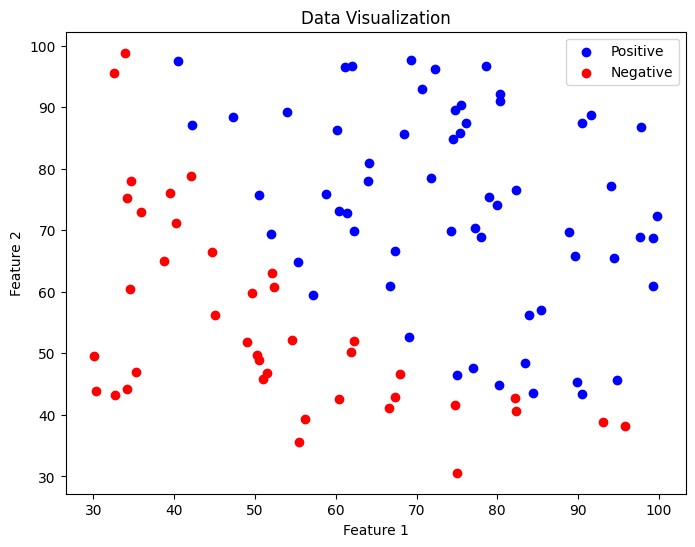

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the data
df = pd.read_csv("ex3data1.csv")
X = df[["feature1", "feature2"]].values
y = df["label"].values.reshape(-1, 1)

# Plot scatter plot
plt.figure(figsize=(8, 6))

plt.scatter(X[y.ravel() == 1, 0], X[y.ravel() == 1, 1], color="blue", label="Positive")

plt.scatter(X[y.ravel() == 0, 0], X[y.ravel() == 0, 1], color="red", label="Negative")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Data Visualization")
plt.legend()
plt.show()

### Part B: Data Preprocessing (2 points)
Normalize the features using z-score normalization.

In [4]:
def standardize_data(X):
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)

    return (X - mean) / std


X_normalized = standardize_data(X)

### Part C: Hypothesis and Cost Function (4 points)

Implement the sigmoid function, the hypothesis function for logistic regression, and the cost function.

Cost Function

$$J(\theta)=\frac{-1}{m}\sum_{i=1}^{m}{\Bigl[y^{(i)}}\log{\bigl(h_\theta(x^{(i)})\bigr)+(1-y^{(i)})\log{\bigl(1-h_\theta(x^{(i)})\bigr)}\Bigr]}$$

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def hypothesis(X, theta):
    return sigmoid(np.dot(X, theta))


def cost_function(X, y, theta):
    m = len(y)
    h = hypothesis(X, theta)

    # Avoid log(0) by clipping predictions
    h = np.clip(h, 1e-15, 1 - 1e-15)

    cost = (-1 / m) * np.sum(y * np.log(h) + (1 - y) * np.log(1 - h))

    return cost

### Part D: Gradient Descent (4 points)
Implement the gradient descent algorithm.

In [6]:
def gradient_descent(X, y, theta, alpha, num_iterations):
    m = len(y)
    J_history = []
    for i in range(num_iterations):
        # Compute hypothesis
        h = hypothesis(X, theta)

        # Compute gradient
        gradient = (1 / m) * np.dot(X.T, (h - y))

        # Update theta
        theta = theta - alpha * gradient

        # Store cost
        J_history.append(cost_function(X, y, theta))

    return theta, J_history

### Part E: Executing Gradient Descent (2 points)
Run the `gradient_descent` function to optimize the model's parameters, then plot the iteration-wise cost history to observe the learning progress.

Optimized theta:
[[0.46741534]
 [1.28615587]
 [1.15327216]]


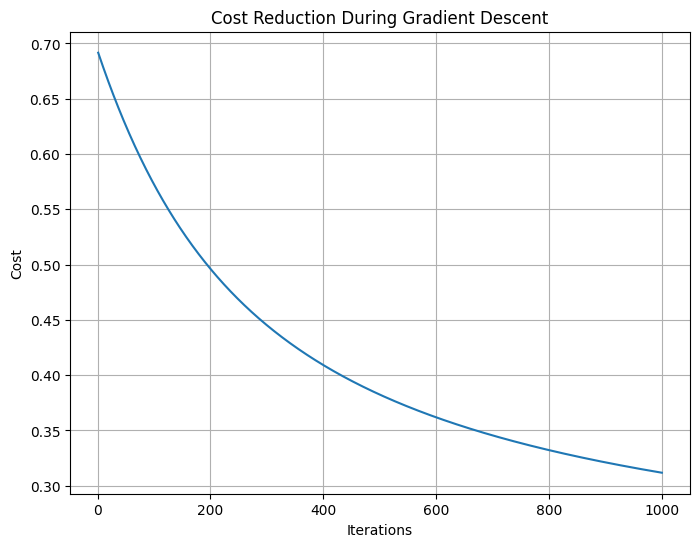

In [7]:
# Add an intercept term to X_normalized
m, n = X_normalized.shape
X_normalized = np.concatenate([np.ones((m, 1)), X_normalized], axis=1)
theta_initial = np.zeros((n + 1, 1))

# Set learning rate and number of iterations
alpha = 0.01
num_iterations = 1000

# Perform gradient descent
theta, J_history = gradient_descent(
    X_normalized, y, theta_initial, alpha, num_iterations
)

print("Optimized theta:")
print(theta)


# Plot the cost reduction
plt.figure(figsize=(8, 6))
plt.plot(range(1, num_iterations + 1), J_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Reduction During Gradient Descent")
plt.grid(True)
plt.show()

### Part F: Plotting the Decision Boundary (3 points)
Implement and call the `plot_decision_boundary` function to visualize how your logistic regression model divides the feature space. 

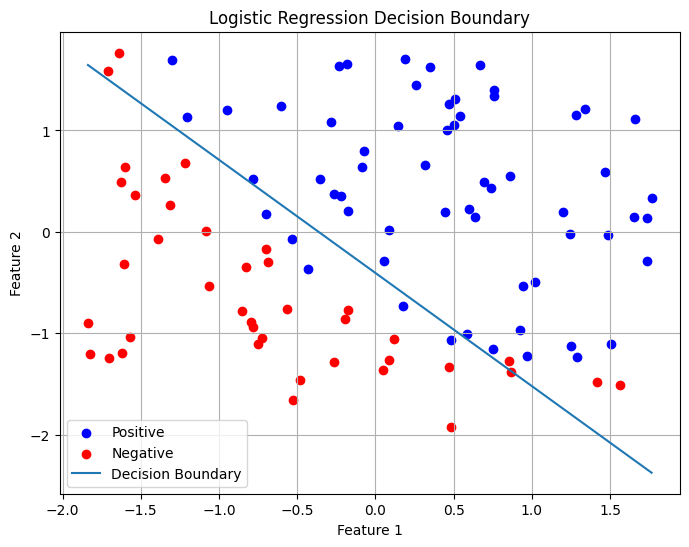

In [8]:
def plot_decision_boundary(X, y, theta):
    # Remove intercept column when plotting feature space
    X_features = X[:, 1:]

    # Plot the data
    plt.figure(figsize=(8, 6))

    plt.scatter(
        X_features[y.ravel() == 1, 0], X_features[y.ravel() == 1, 1], color="blue", label="Positive"
    )

    plt.scatter(
        X_features[y.ravel() == 0, 0], X_features[y.ravel() == 0, 1], color="red", label="Negative"
    )

    # Decision boundary:
    # theta_0 + theta_1*x1 + theta_2*x2 = 0
    x_values = np.linspace(X_features[:, 0].min(), X_features[:, 0].max(), 100)

    y_values = -(theta[0] + theta[1] * x_values) / theta[2]

    plt.plot(x_values, y_values, label="Decision Boundary")

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title("Logistic Regression Decision Boundary")
    plt.legend()
    plt.grid(True)
    plt.show()


# Call the plot_decision_boundary function
plot_decision_boundary(X_normalized, y, theta)

### Part G: Model Evaluation (3 points)
Use the predict function to generate predictions for your dataset and then create a confusion matrix, then calculate and display the accuracy, precision, recall, and F1 score to evaluate the performance of your model.

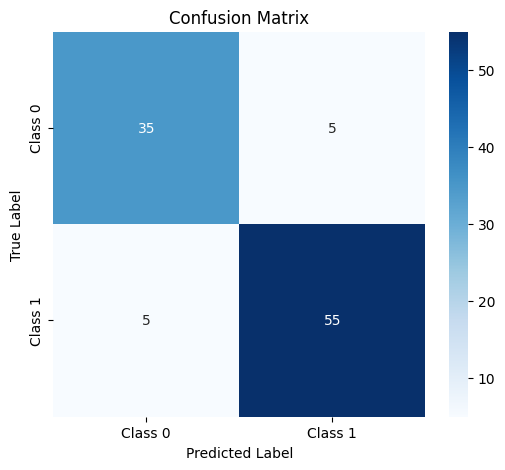

Accuracy:  0.9000
Precision: 0.9167
Recall:    0.9167
F1 Score:  0.9167


In [9]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


def predict(X, theta):
    probs = sigmoid(np.dot(X, theta))
    return (probs >= 0.5).astype(int)


# Make predictions
y_pred = predict(X_normalized, theta)


# Generate confusion matrix
conf_matrix = confusion_matrix(y, y_pred)


# Plotting the confusion matrix using seaborn
plt.figure(figsize=(6, 5))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"],
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


# Calculate and print performance metrics
accuracy = accuracy_score(y, y_pred)
precision = precision_score(y, y_pred, zero_division=0)
recall = recall_score(y, y_pred, zero_division=0)
f1 = f1_score(y, y_pred, zero_division=0)

# Print metrics
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

### Part H: Impact of Learning Rates on Model Convergence (3 points)
Experiment with multiple learning rates, plot the cost histories for each, and **analyze how the speed and stability of convergence change with different learning rates**.

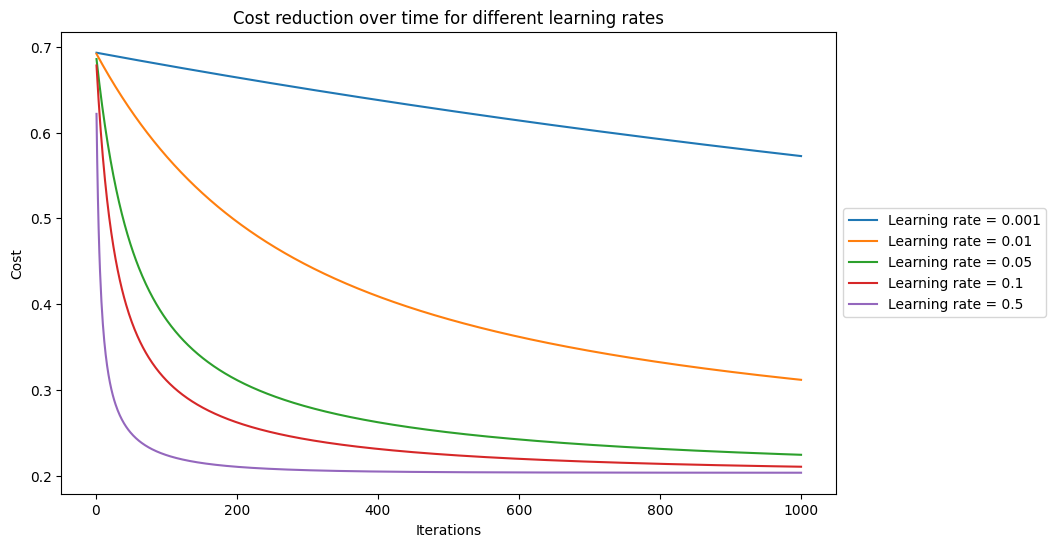

In [10]:
# Set different learning rates
learning_rates = [0.001, 0.01, 0.05, 0.1, 0.5]

# Dictionary to store the cost histories for different learning rates
cost_histories = {}

for alpha in learning_rates:
    # Use a fresh copy of the initial parameters
    theta_start = theta_initial.copy()

    theta_lr, J_history_lr = gradient_descent(
        X_normalized, y, theta_start, alpha, num_iterations
    )

    cost_histories[alpha] = J_history_lr


# Plotting the cost history for each learning rate
plt.figure(figsize=(10, 6))

for alpha, history in cost_histories.items():
    plt.plot(range(1, num_iterations + 1), history, label=f"Learning rate = {alpha}")


plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost reduction over time for different learning rates")

# Place the legend outside the plot
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))

plt.show()

### Part I: Examining the Effects of Not Normalizing Data (2 points)
Apply gradient descent on raw data using a moderate learning rate. Plot the cost reduction over iterations, and also the decision boundary for non-standardized data.

Make predictions using the model and generate a confusion matrix to assess classification accuracy. Then calculate and print the accuracy, precision, recall, and F1 score. **Discuss the results**.

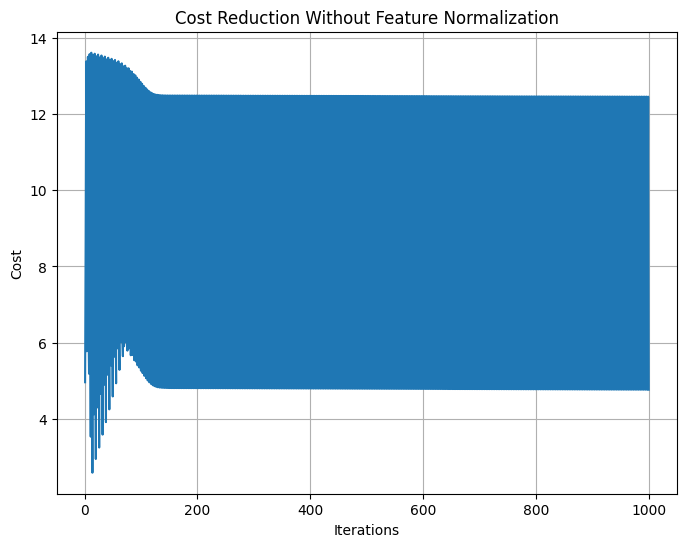

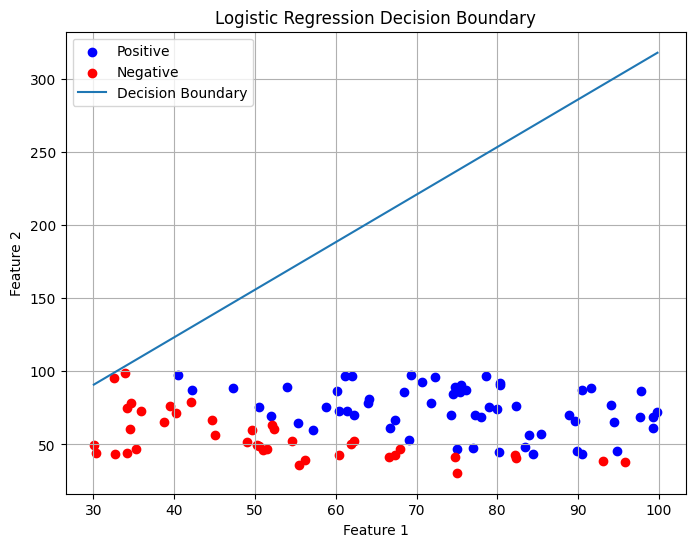

In [16]:
# Preparing raw data with an intercept term
m, n = X.shape
X_raw = np.concatenate([np.ones((m, 1)), X], axis=1)
theta_raw_initial = np.zeros((n + 1, 1))

# Using a moderate learning rate
alpha_raw = 0.01

theta_raw, J_history_raw = gradient_descent(
    X_raw, y, theta_raw_initial, alpha_raw, num_iterations
)


# Plotting cost over iterations for non-standardized data
plt.figure(figsize=(8, 6))

plt.plot(range(1, num_iterations + 1), J_history_raw)

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Reduction Without Feature Normalization")
plt.grid(True)
plt.show()


# Plotting the decision boundary for non-standardized data
plot_decision_boundary(X_raw, y, theta_raw)

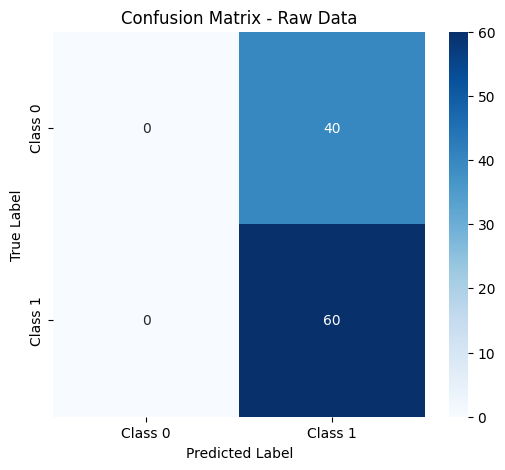

Accuracy:  0.6000
Precision: 0.6000
Recall:    1.0000
F1 Score:  0.7500


In [18]:
# Make predictions
y_pred_raw = predict(X_raw, theta_raw)

# Generate confusion matrix
conf_matrix_raw = confusion_matrix(y, y_pred_raw)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    conf_matrix_raw,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"],
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Raw Data")
plt.show()


# Calculate metrics
accuracy_raw = accuracy_score(y, y_pred_raw)
precision_raw = precision_score(y, y_pred_raw, zero_division=0)
recall_raw = recall_score(y, y_pred_raw, zero_division=0)
f1_raw = f1_score(y, y_pred_raw, zero_division=0)


# Print metrics
print(f"Accuracy:  {accuracy_raw:.4f}")
print(f"Precision: {precision_raw:.4f}")
print(f"Recall:    {recall_raw:.4f}")
print(f"F1 Score:  {f1_raw:.4f}")

<a id='2'></a>
## Logistic Regression with Multiple Features (9 points)

### Part A: Load and Prepare Data (3 points)
Standardize the dataset features and split it into training and testing sets.

In [19]:
from sklearn.datasets import load_breast_cancer

# Load the dataset
data = load_breast_cancer()
cancer_df = pd.DataFrame(data.data, columns=data.feature_names)
cancer_df['target'] = data.target

# Display the last 5 rows of the dataset
cancer_df.tail()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,1


In [20]:
from sklearn.model_selection import train_test_split

# Standardize the data
X = data.data
y = data.target.reshape(-1, 1)  # Ensure y is a column vector

# Split the data into training and testing sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Calculate mean and standard deviation using ONLY the training data
X_train_mean = np.mean(X_train_raw, axis=0)
X_train_std = np.std(X_train_raw, axis=0)

# Standardize training and testing data using training statistics
X_train = (X_train_raw - X_train_mean) / X_train_std
X_test = (X_test_raw - X_train_mean) / X_train_std


# Add intercept term
X_train = np.concatenate([np.ones((X_train.shape[0], 1)), X_train], axis=1)

X_test = np.concatenate([np.ones((X_test.shape[0], 1)), X_test], axis=1)

# The resulting dimensions are:
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training set shape: (455, 31)
Testing set shape: (114, 31)
Training labels shape: (455, 1)
Testing labels shape: (114, 1)


### Part B: Executing Gradient Descent (2 points)
Initialize parameters and run the `gradient_descent` function to minimize the cost function. Then plot the iteration-wise cost history to observe the learning progress.

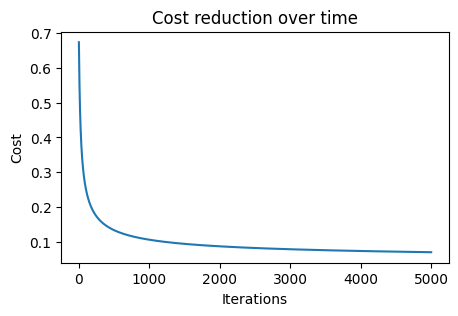

In [ ]:
# Initialize theta
theta_initial = np.zeros((X_train.shape[1], 1))


# Set learning rate and number of iterations
alpha = 0.01
num_iterations = 5000


# Perform gradient descent
theta, J_history = gradient_descent(
    X_train, y_train, theta_initial, alpha, num_iterations
)

print("Optimized theta:")
print(theta)

# Plot the cost reduction
plt.figure(figsize=(8, 6))

plt.plot(range(1, num_iterations + 1), J_history)

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Reduction for Multiple-Feature Logistic Regression")
plt.grid(True)
plt.show()

### Part C: Prediction and Evaluate the Best Model (4 points)
Test multiple learning rates to find the most effective one for this dataset. Implement the loop to iterate over learning rates and store the results.

After that use the model with the best learning rate to make predictions on the test set and evaluate its performance. Implement the prediction and evaluation section.

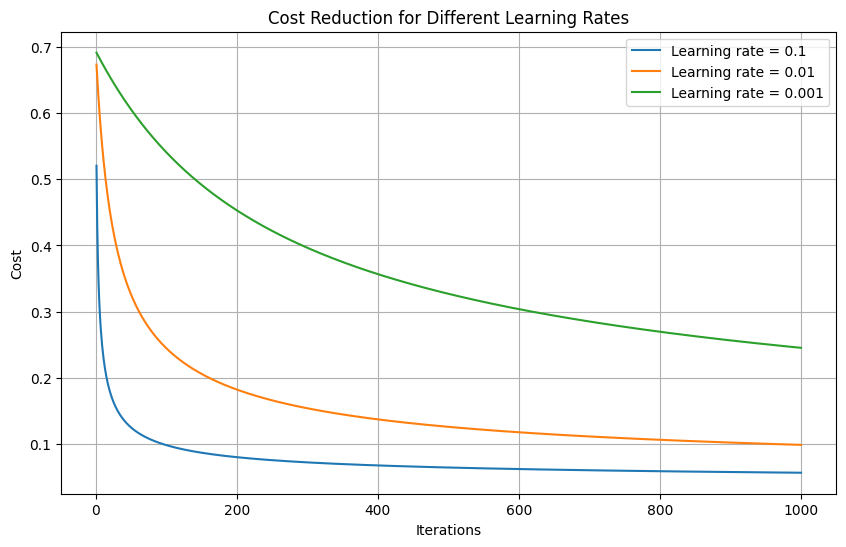

The best learning rate is: 0.1 with a final cost of 0.056602


In [21]:
learning_rates = [0.1, 0.01, 0.001]
models = {}
final_costs = {}

# Loop through learning rates, run gradient descent, and store results
for alpha in learning_rates:

    # Initialize theta for this learning rate
    theta_initial_lr = np.zeros((X_train.shape[1], 1))

    # Run gradient descent
    theta_lr, J_history_lr = gradient_descent(
        X_train, y_train, theta_initial_lr, alpha, num_iterations
    )

    # Store model parameters and cost history
    models[alpha] = {"theta": theta_lr, "J_history": J_history_lr}

    # Store final cost
    final_costs[alpha] = J_history_lr[-1]


# Plot cost histories for each learning rate
plt.figure(figsize=(10, 6))

for alpha in learning_rates:
    plt.plot(
        range(1, num_iterations + 1),
        models[alpha]["J_history"],
        label=f"Learning rate = {alpha}",
    )

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Reduction for Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()


# Identify the best learning rate based on the lowest final cost
best_alpha = min(final_costs, key=final_costs.get)
print(
    f"The best learning rate is: {best_alpha} with a final cost of {final_costs[best_alpha]:.6f}"
)

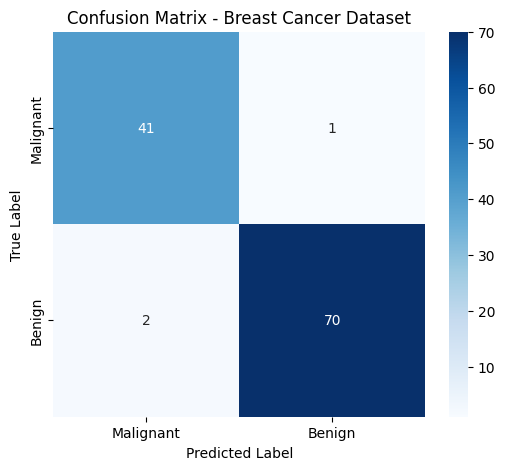

Accuracy:  0.9737
Precision: 0.9859
Recall:    0.9722
F1 Score:  0.9790


In [22]:
# Get the model corresponding to the best learning rate
best_theta = models[best_alpha]['theta']


# Make predictions on the test set
y_pred = predict(
    X_test,
    best_theta
)


# Generate confusion matrix
conf_matrix = confusion_matrix(
    y_test,
    y_pred
)


# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Malignant', 'Benign'],
    yticklabels=['Malignant', 'Benign']
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Breast Cancer Dataset')
plt.show()


# Calculate performance metrics
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)


# Print metrics
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

<a id='3'></a>
## Non-Linear Classifier (13 points)

### Part A: Load and Visualize Data (2 points)
Plot the data.

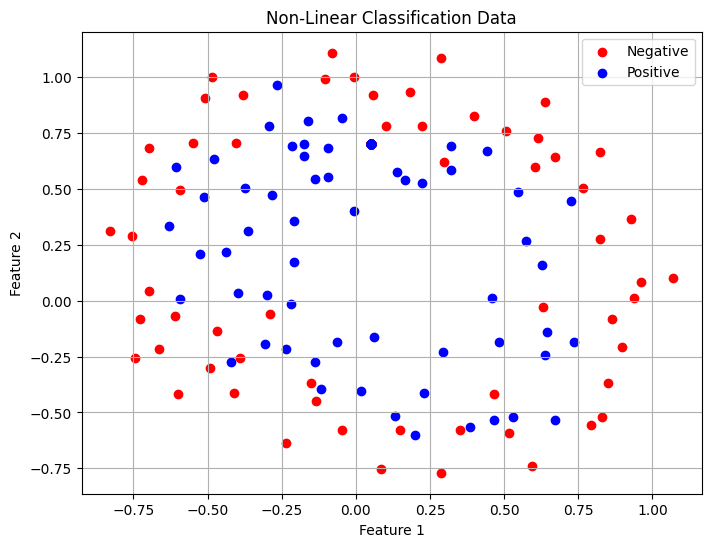

In [ ]:
# Load data
df = pd.read_csv("ex3data2.csv")
X = df[["feature1", "feature2"]].values
y = df["label"].values.reshape(-1, 1)

pos = np.where(y == 1)
neg = np.where(y == 0)

# Scatter plot of the data
plt.figure(figsize=(8, 6))

plt.scatter(X[pos, 0], X[pos, 1], color="blue", label="Positive")

plt.scatter(X[neg, 0], X[neg, 1], color="red", label="Negative")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Non-Linear Classification Data")
plt.legend()
plt.grid(True)
plt.show()

### Part B: Feature Expansion (4 points)
One way to better separate the data is to create more features from each data point. The `expand_features` function will expand the features into all polynomial terms of $x_1$ and $x_2$ up to a dpecified degree.

For instance, for degree $6$:

`expand_features(x1, x2)=` $\begin{bmatrix} 1 \\ x_1 \\x_2 \\ {x_1}^2 \\ x_1x_2 \\ {x_2}^2 \\ \vdots \\ x_1{x_2}^5 \\ {x_2}^6 \end{bmatrix}$

This mapping transforms our 2-dimensional input into a 28-dimensional feature vector, allowing for a more complex and nonlinear decision boundary.

Implement the `expand_features` function and apply it to the dataset.

In [26]:
def expand_features(x1, x2):
    features = [1, x1, x2]

    # Adding terms as specified up to x1*x2^5 and x2^6
    for i in range(2, 7):
        for j in range(i, -1, -1):
            features.append((x1**j) * (x2 ** (i - j)))

    return features


# Apply feature expansion to each sample
X_poly = np.array([expand_features(x1, x2) for x1, x2 in X])

print("Original feature shape:", X.shape)
print("Polynomial feature shape:", X_poly.shape)

Original feature shape: (118, 2)
Polynomial feature shape: (118, 28)


### Part C: Executing Gradient Descent (3 points)
Initialize parameters and run the `gradient_descent` function to minimize the cost function with different learning rates. Then plot the cost histories for each learning rate and identify the best learning rate.

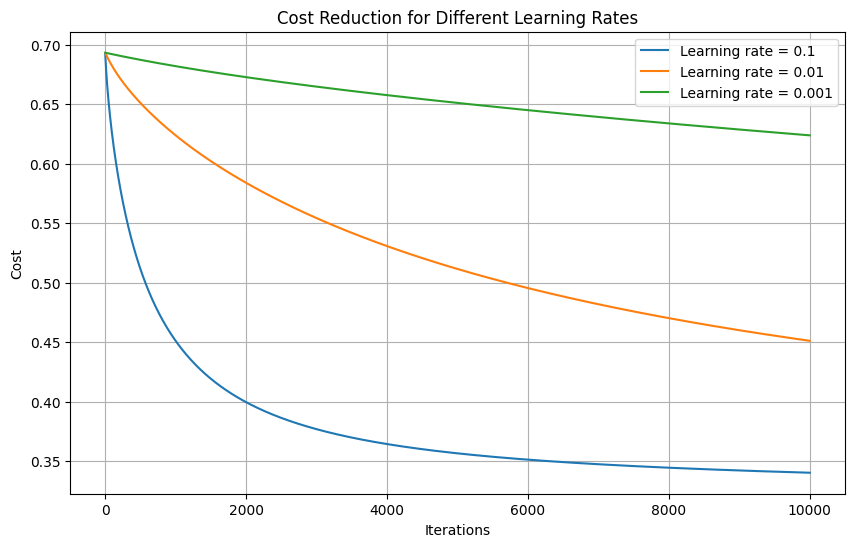

The best learning rate is: 0.1 with a final cost of 0.340419


In [27]:
# Initialize parameters
num_iterations = 10000
learning_rates = [0.1, 0.01, 0.001]
models = {}
final_costs = {}

for alpha in learning_rates:
    theta_initial = np.zeros((X_poly.shape[1], 1))

    # Perform gradient descent
    theta, J_history = gradient_descent(X_poly, y, theta_initial, alpha, num_iterations)

    # Store the model and its cost history
    models[alpha] = {"theta": theta, "J_history": J_history}

    # Store final cost
    final_costs[alpha] = J_history[-1]


# Plot cost histories for each learning rate
plt.figure(figsize=(10, 6))

for alpha in learning_rates:
    plt.plot(
        range(1, num_iterations + 1),
        models[alpha]["J_history"],
        label=f"Learning rate = {alpha}",
    )

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Reduction for Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()


# Identify the best learning rate based on the lowest final cost
best_alpha = min(final_costs, key=final_costs.get)

best_theta = models[best_alpha]["theta"]

print(
    f"The best learning rate is: {best_alpha} "
    f"with a final cost of {final_costs[best_alpha]:.6f}"
)

### Part D: Evaluate the Best Model (2 points)
Evaluate the best model's performance.


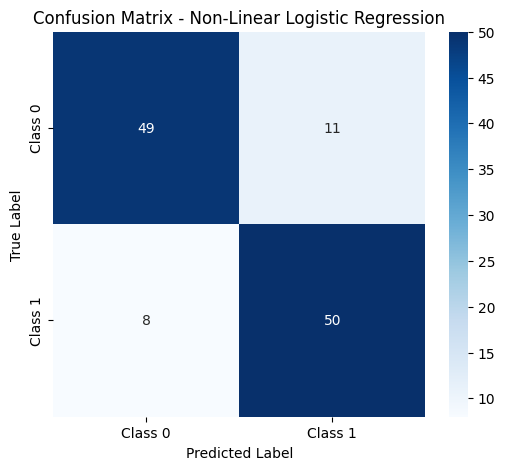

Accuracy:  0.8390
Precision: 0.8197
Recall:    0.8621
F1 Score:  0.8403


In [28]:
# Make predictions
y_pred = predict(X_poly, best_theta)


# Generate confusion matrix
conf_matrix = confusion_matrix(y, y_pred)


# Plotting confusion matrix using seaborn
plt.figure(figsize=(6, 5))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"],
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Non-Linear Logistic Regression")
plt.show()


# Calculate and print performance metrics
accuracy = accuracy_score(y, y_pred)

precision = precision_score(y, y_pred, zero_division=0)

recall = recall_score(y, y_pred, zero_division=0)

f1 = f1_score(y, y_pred, zero_division=0)


# Print metrics
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

### Part E: Plot Decision Boundary (2 points)
Calculate and plot the decision boundary.

**Analyze the decision boundary by plotting it. How well does the model separate the classes? Discuss the importance of feature expansion in non-linear logistic regression.**

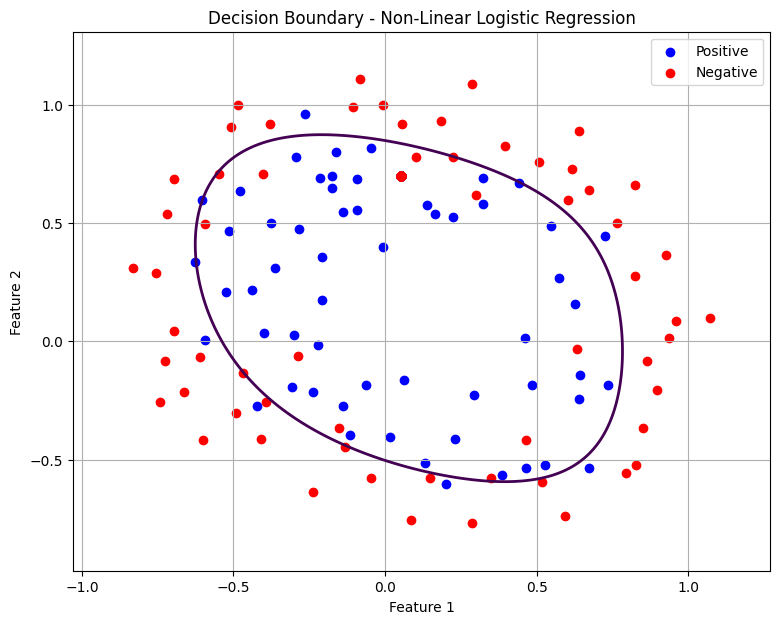

In [31]:
# Scatter plot of the data
plt.figure(figsize=(9, 7))

plt.scatter(X[pos, 0], X[pos, 1], color="blue", label="Positive")

plt.scatter(X[neg, 0], X[neg, 1], color="red", label="Negative")

# Define the grid range
x1_min, x1_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
x2_min, x2_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 500), np.linspace(x2_min, x2_max, 500)
)

# Expand grid to polynomial features (make sure this matches your expansion in training)
grid = np.c_[xx1.ravel(), xx2.ravel()]
X_grid_poly = np.array(
    [expand_features(x1, x2) for x1, x2 in grid]
)  # Assuming expand_features is defined

# Predict using the polynomial model
Z = hypothesis(X_grid_poly, best_theta)

Z = Z.reshape(xx1.shape)

# Plot decision boundary
plt.contour(xx1, xx2, Z, levels=[0.5], linewidths=2)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Decision Boundary - Non-Linear Logistic Regression")
plt.legend()
plt.grid(True)
plt.show()

<a id='4'></a>
## Regularized Logistic Regression (15 points)

### Part A: Load and Visualize Data (2 points)
Load the training and testing datasets and create scatter plots to visualize the data. We will use subplots to show both the training and testing data in a single figure.

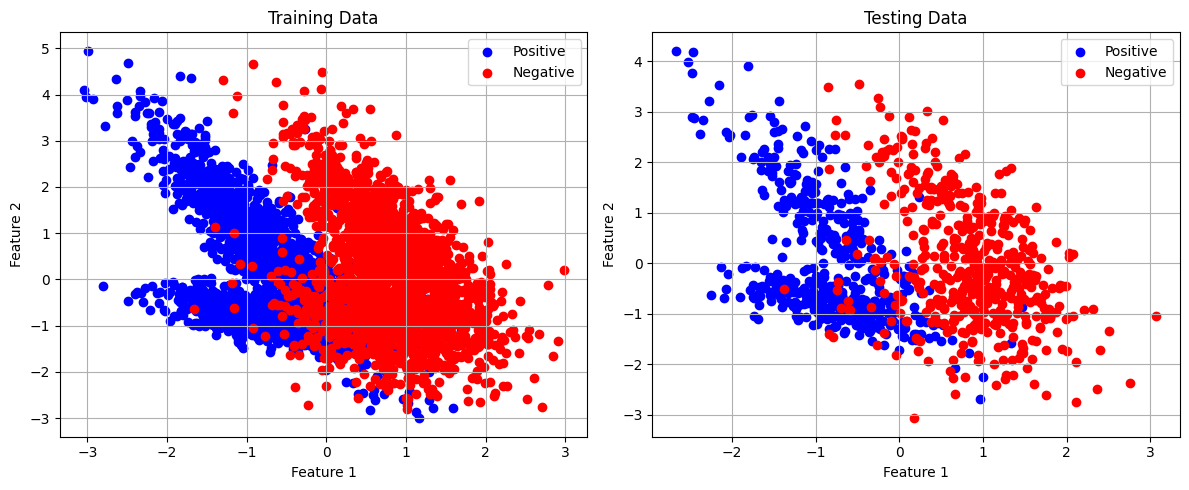

In [36]:
# Load data
df_train = pd.read_csv("Syndata-train.csv")
df_test = pd.read_csv("Syndata-test.csv")

# Extract features and labels
X_train = df_train[["feature1", "feature2"]].values
y_train = df_train["label"].values.reshape(-1, 1)
X_test = df_test[["feature1", "feature2"]].values
y_test = df_test["label"].values.reshape(-1, 1)

# Scatter plot
plt.figure(figsize=(12, 5))

# Training data
plt.subplot(1, 2, 1)

plt.scatter(
    X_train[y_train.ravel() == 0, 0],
    X_train[y_train.ravel() == 0, 1],
    color="blue",
    label="Positive",
)

plt.scatter(
    X_train[y_train.ravel() == 1, 0],
    X_train[y_train.ravel() == 1, 1],
    color="red",
    label="Negative",
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Training Data")
plt.legend()
plt.grid(True)

# Create subplot for testing data
plt.subplot(1, 2, 2)

plt.scatter(
    X_test[y_test.ravel() == 0, 0],
    X_test[y_test.ravel() == 0, 1],
    color="blue",
    label="Positive",
)

plt.scatter(
    X_test[y_test.ravel() == 1, 0],
    X_test[y_test.ravel() == 1, 1],
    color="red",
    label="Negative",
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Testing Data")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Part B: Polynomial Feature Transformation (2 points)
Apply polynomial feature transformation to the training and testing data. Use `PolynomialFeatures` from `sklearn.preprocessing`.

In [37]:
from sklearn.preprocessing import PolynomialFeatures

# Polynomial feature transformation
poly = PolynomialFeatures(degree=4, include_bias=True)

# Apply the transformation to X_train and X_test
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

print("Original training shape:", X_train.shape)
print("Polynomial training shape:", X_train_poly.shape)

print("Original testing shape:", X_test.shape)
print("Polynomial testing shape:", X_test_poly.shape)

Original training shape: (4000, 2)
Polynomial training shape: (4000, 15)
Original testing shape: (1000, 2)
Polynomial testing shape: (1000, 15)


### Part C: Cost Function and Gradient Descent with Regularization (5 points)
Implement the cost function and gradient descent algorithm with $l1$ and $l2$ regularization.

In [38]:
def cost_function(X, y, theta, lambda_, reg_type="l2"):
    m = len(y)
    h = hypothesis(X, theta)

    # Prevent log(0)
    h = np.clip(h, 1e-15, 1 - 1e-15)

    # Standard logistic regression cost
    cost = (-1 / m) * np.sum(y * np.log(h) + (1 - y) * np.log(1 - h))

    # Do not regularize the intercept
    theta_reg = theta.copy()
    theta_reg[0] = 0

    if reg_type == "l2":
        # Calculate L2 regularization term
        reg = (lambda_ / (2 * m)) * np.sum(theta_reg**2)

    elif reg_type == "l1":
        # Calculate L1 regularization term
        reg = (lambda_ / m) * np.sum(np.abs(theta_reg))

    else:
        reg = 0

    # Calculate the cost with regularization
    return cost + reg


def gradient_descent(X, y, theta, alpha, num_iterations, lambda_, reg_type="l2"):
    m = len(y)
    J_history = []

    for i in range(num_iterations):
        h = hypothesis(X, theta)
        # Calculate the gradient
        gradient = (1 / m) * np.dot(X.T, (y - h))

        # Do not regularize the intercept
        theta_reg = theta.copy()
        theta_reg[0] = 0

        if reg_type == "l2":
            # Adjust the gradient for L2 regularization
            regularization = (lambda_ / m) * theta_reg

            # Update theta
            theta += alpha * (gradient - regularization)

        elif reg_type == "l1":
            # Adjust the gradient for L1 regularization
            regularization = (lambda_ / m) * np.sign(theta_reg)

            # Update theta
            theta += alpha * (gradient - regularization)

        else:
            theta += alpha * gradient  # No regularization

        J_history.append(cost_function(X, y, theta, lambda_, reg_type))

    return theta, J_history

### Part D: Training and Evaluating the Model (3 points)
Train the model with different learning rates and regularization strengths, and evaluate the performance.

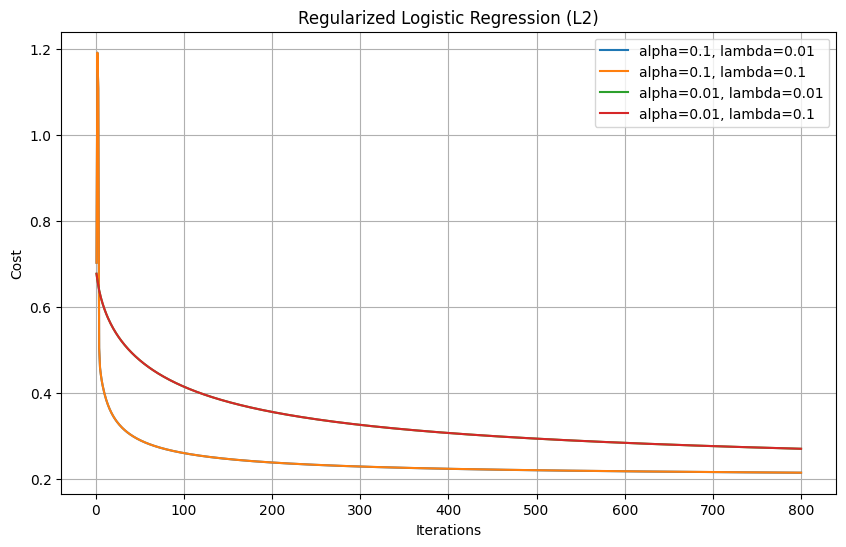

Best learning rate: 0.1
Best regularization strength: 0.01
Lowest final cost: 0.214259


In [39]:
# Gradient descent parameters
num_iterations = 800
learning_rates = [0.1, 0.01]
regularization_strengths = [0.01, 0.1]
models = {}
final_costs = {}

# Choose the regularization type
reg_type = "l2"

for alpha in learning_rates:
    for lambda_ in regularization_strengths:
        # Initialize theta
        theta_initial = np.zeros((X_train_poly.shape[1], 1))

        # Perform gradient descent and store the results
        theta, J_history = gradient_descent(
            X_train_poly,
            y_train,
            theta_initial,
            alpha,
            num_iterations,
            lambda_,
            reg_type,
        )

        # Store model
        models[(alpha, lambda_)] = (theta, J_history)

        # Store final cost
        final_costs[(alpha, lambda_)] = J_history[-1]

# Plotting cost over iteration
plt.figure(figsize=(10, 6))

for (alpha, lambda_), (theta, J_history) in models.items():

    plt.plot(
        range(1, num_iterations + 1),
        J_history,
        label=f"alpha={alpha}, lambda={lambda_}",
    )

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title(f"Regularized Logistic Regression ({reg_type.upper()})")
plt.legend()
plt.grid(True)
plt.show()


# Best parameters
best_params = min(final_costs, key=final_costs.get)

best_alpha, best_lambda = best_params

print(f"Best learning rate: {best_alpha}")

print(f"Best regularization strength: {best_lambda}")

print(f"Lowest final cost: {final_costs[best_params]:.6f}")

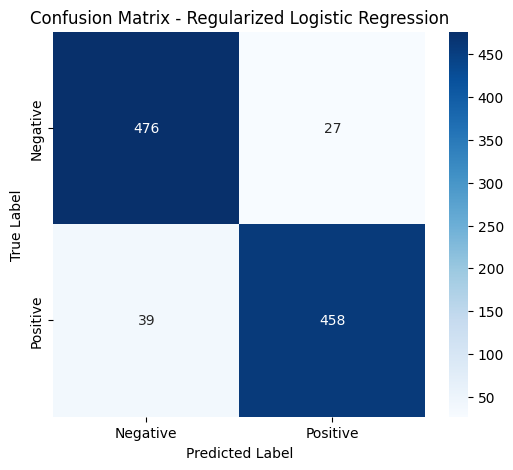

Accuracy:  0.9340
Precision: 0.9443
Recall:    0.9215
F1 Score:  0.9328


In [40]:
best_theta = models[best_alpha, best_lambda][0]

# Make predictions
y_pred = predict(X_test_poly, best_theta)

# Generate confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)


# Plotting confusion matrix using seaborn

plt.figure(figsize=(6, 5))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"],
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Regularized Logistic Regression")
plt.show()


# Calculate and print performance metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)


# Print metrics
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

### Part E: Plot Decision Boundary (3 points)
Plot the decision boundary for both the training and testing data.

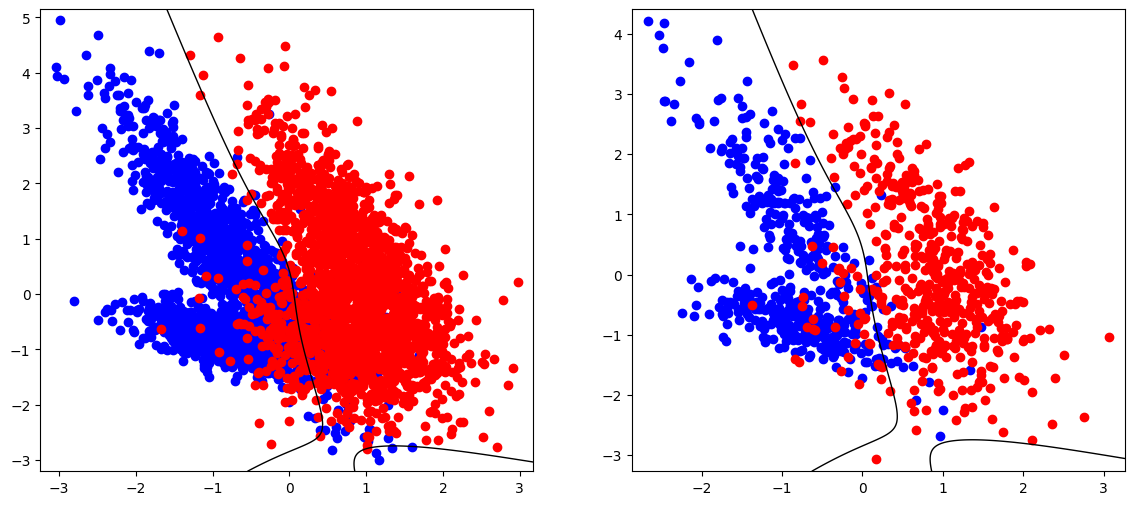

In [44]:
# Define polynomial transformation
poly = PolynomialFeatures(degree=4, include_bias=True)


# Helper function to plot data and decision boundary
def plot_data_and_boundary(X, y, theta, subplot_index, title):
    # Define subplot
    plt.subplot(1, 2, subplot_index)

    # Scatter plot of the data
    pos = np.where(y.ravel() == 1)
    neg = np.where(y.ravel() == 0)

    plt.scatter(X[neg, 0], X[neg, 1], color="blue", label="Positive")

    plt.scatter(X[pos, 0], X[pos, 1], color="red", label="Negative")

    # Prepare grid for decision boundary
    x1_min, x1_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    x2_min, x2_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
    xx1, xx2 = np.meshgrid(
        np.linspace(x1_min, x1_max, 500), np.linspace(x2_min, x2_max, 500)
    )
    grid = np.c_[xx1.ravel(), xx2.ravel()]
    grid_poly = poly.fit_transform(grid)  # Transform grid

    # Predict using the polynomial model
    Z = sigmoid(np.dot(grid_poly, theta))
    Z = Z.reshape(xx1.shape)

    # Plot decision boundary
    plt.contour(xx1, xx2, Z, levels=[0.5], colors="black", linewidths=1)


# Best theta obtained from training
best_theta = models[(best_alpha, best_lambda)][0]

# Create figure
plt.figure(figsize=(14, 6))

# Plot for Training Data
plot_data_and_boundary(X_train, y_train, best_theta, 1, "Training Data")

# Plot for Testing Data
plot_data_and_boundary(X_test, y_test, best_theta, 2, "Testing Data")


# Show plots
plt.show()

<a id='5'></a>
## Multiclass Logistic Regression (8 points)

### Part A: Load and Preprocess Data: (3 points)
Load the **MNIST** dataset and configure the cross-validation procedure. Use `StratifiedKFold` with **10** folds for cross-validation. Utilize the `LogisticRegression` function from `sklearn.linear_model`, setting `max_iter=1000` and `solver='lbfgs'`. You must set one other parameter. **What parameter?**

A pipeline is a sequence of data processing steps. Use it to streamline the process by combining `StandardScaler` and `LogisticRegression`. The pipeline ensures that the data is scaled before fitting the model.

In [45]:
from sklearn.datasets import fetch_openml
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Load MNIST data
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)

# Configure the cross-validation procedure
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Initialize LogisticRegression with max_iter=1000, solver='lbfgs', ???
log_reg = LogisticRegression(max_iter=1000, solver="lbfgs", C=1.0)

# Create a pipeline
pipeline = make_pipeline(StandardScaler(), log_reg)

print("Data shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of CV folds:", cv.n_splits)

Data shape: (70000, 784)
Labels shape: (70000,)
Number of CV folds: 10


### Part B: Train and Evaluate the Model (3 points)
Train the model using cross-validation, evaluate its performance, and save the best model using `joblib`.

In [46]:
import joblib

fold = 0
best_accuracy = 0
best_model = None

for train_idx, test_idx in cv.split(X, y):
    fold += 1
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # Fit the model
    pipeline.fit(X_train, y_train)

    # Find the accuracy for test set
    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    print(f"Fold {fold}: Accuracy = {accuracy:.4f}")

    # Check if the current model is the best one
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_model = pipeline
        # Save the best model
        joblib.dump(best_model, "best_mnist_logistic_regression.pkl")

print(f"Best Model Saved with Accuracy: {best_accuracy:.4f}")

Fold 1: Accuracy = 0.9169
Fold 2: Accuracy = 0.9171
Fold 3: Accuracy = 0.9243
Fold 4: Accuracy = 0.9136
Fold 5: Accuracy = 0.9169
Fold 6: Accuracy = 0.9154
Fold 7: Accuracy = 0.9166
Fold 8: Accuracy = 0.9230
Fold 9: Accuracy = 0.9174
Fold 10: Accuracy = 0.9119
Best Model Saved with Accuracy: 0.9243


### Part C: Load the Model and Make Predictions (2 points)
Load the best model you saved using `joblib` and make predictions on a sample of 10 randomly selected images. Visualize the images along with the predicted labels and the actual labels.

**Why is saving and loading models important? Explain the significance of training and saving models once, and then loading them for future use without retraining.**

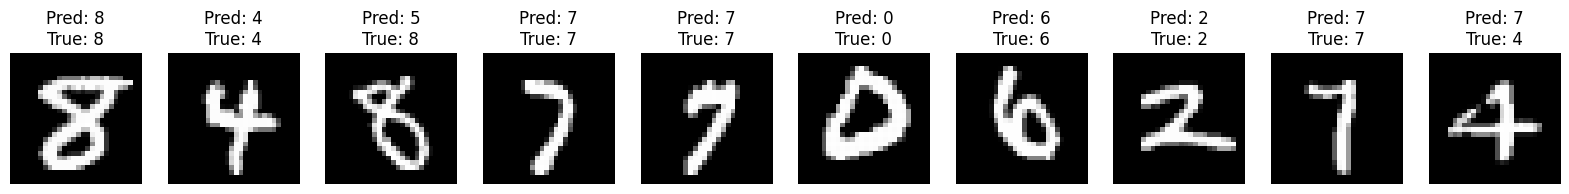

In [47]:
# Load the model
loaded_model = joblib.load("best_mnist_logistic_regression.pkl")


# Select 10 random images from the dataset
np.random.seed(42)

indices = np.random.choice(len(X), size=10, replace=False)

selected_images = X[indices]
selected_labels = y[indices]

# Predict using the loaded model
predicted_labels = loaded_model.predict(selected_images)


# Plotting the images with predicted and actual labels
fig, axes = plt.subplots(1, 10, figsize=(20, 4))
for i, ax in enumerate(axes):
    ax.imshow(selected_images[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
    ax.set_title(f"Pred: {predicted_labels[i]}\nTrue: {selected_labels[i]}")
plt.show()